# ICC Men's T20 World Cup: Delivery Telemetry & Match Momentum (EDA)

## Project Overview
This exploratory data analysis examines ball-by-ball delivery event logs across ICC Men's T20 World Cup tournaments.

Instead of traditional match-level scorecards, we analyze in-match telemetry: phase-wise scoring velocity (Powerplay, Middle, Death), dot-ball pressure, and dismissal hazard rates—replicating the analytical pipelines behind live broadcast analytics engines (like CricViz and television graphic systems).

### Objectives
1. Inspect schema health, delivery integrity, and handle event-based null allocations.
2. Engineer situational features: over normalization, match phases (Powerplay, Middle, Death), and ball outcome classifications.
3. Quantify scoring acceleration, dot-ball ratios, and boundary frequencies across match phases.
4. Chart the over-by-over scoring velocity curve across all 20 overs.
5. Profile international batter efficiency using Strike Rate versus Dot-Ball concession ratios.
6. Analyze dismissal modes and evaluate delivery attribute correlations.

In [29]:
# NumPy: Used for fast numerical operations and arrays
import numpy as np

# Pandas: The core tool for loading, cleaning, grouping, and manipulating tabular data
import pandas as pd

# Matplotlib & Seaborn: Used for building statistical data visualisations
import matplotlib.pyplot as plt
import seaborn as sns

# Set clean visual defaults for all plots
sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10

In [30]:
import os
import urllib.request
import zipfile
import pandas as pd

# 1. Download official ICC Men's T20 World Cup ball-by-ball zip (only ~1.5 MB)
url = "https://cricsheet.org/downloads/icc_mens_t20_world_cup_csv2.zip"
urllib.request.urlretrieve(url, "t20_world_cup.zip")

# 2. Extract in Colab session
with zipfile.ZipFile("t20_world_cup.zip", "r") as zip_ref:
  zip_ref.extractall("t20_wc_data")

# 3. Load the single consolidated deliveries file ('all_matches.csv')
df = pd.read_csv("t20_wc_data/all_matches.csv")

print(
    f"Dataset Shape: {df.shape[0]} international balls bowled across"
    f" {df.shape[1]} columns"
)
df.head()

Dataset Shape: 52521 international balls bowled across 27 columns


,match_id,season,start_date,venue,innings,ball,actual_delivery,batting_team,bowling_team,striker,...,legbyes,penalty,non_boundary,wicket_type,player_dismissed,other_wicket_type,other_player_dismissed,fielder_1,fielder_2,fielder_3
0,1273712,2021/22,2021-10-17,Al Amerat Cricket Ground Oman Cricket (Ministr...,1,0.1,0.1,Papua New Guinea,Oman,TP Ura,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1273712,2021/22,2021-10-17,Al Amerat Cricket Ground Oman Cricket (Ministr...,1,0.2,0.2,Papua New Guinea,Oman,TP Ura,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1273712,2021/22,2021-10-17,Al Amerat Cricket Ground Oman Cricket (Ministr...,1,0.3,0.3,Papua New Guinea,Oman,TP Ura,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1273712,2021/22,2021-10-17,Al Amerat Cricket Ground Oman Cricket (Ministr...,1,0.4,0.4,Papua New Guinea,Oman,TP Ura,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1273712,2021/22,2021-10-17,Al Amerat Cricket Ground Oman Cricket (Ministr...,1,0.5,0.5,Papua New Guinea,Oman,TP Ura,...,NaN,NaN,NaN,bowled,TP Ura,NaN,NaN,NaN,NaN,NaN


## 1. Data Health Check & Event-Based Null Treatment
In ball-by-ball telemetry, missing values in extras and dismissals represent non-events (e.g., no extra run was conceded, or no wicket fell on that delivery). We audit these columns and standardize headers.

In [31]:
# Standardize column headers: lower case, remove leading/trailing spaces, use underscores
df.columns = df.columns.str.strip().str.replace(' ', '_').str.lower()

# Audit missing values
print('Columns with missing values before treatment:')
print(df.isnull().sum()[df.isnull().sum() > 0])

# Domain-specific null treatment:
# 1. Fill non-event extra columns with 0
extras_cols = ['wides', 'noballs', 'byes', 'legbyes', 'penalty']
for col in extras_cols:
  if col in df.columns:
    df[col] = df[col].fillna(0)

# 2. Label deliveries with no wicket explicitly
df['wicket_type'] = df['wicket_type'].fillna('None')

# 3. Create a clean binary indicator for dismissals (1 = Wicket, 0 = No wicket)
df['is_wicket'] = df['player_dismissed'].notnull().astype(int)

# Check for duplicate delivery rows
print(f'\nExact Duplicate Rows: {df.duplicated().sum()}')

Columns with missing values before treatment:
wides                     50818
noballs                   52313
byes                      52367
legbyes                   51676
penalty                   52517
non_boundary              52513
wicket_type               49620
player_dismissed          49620
other_wicket_type         52521
other_player_dismissed    52521
fielder_1                 50469
fielder_2                 52402
fielder_3                 52521
dtype: int64

Exact Duplicate Rows: 0


## 2. Feature Engineering: Match Phases & Outcome Categorization
We engineer situational domain features:
- `over_number`: Extracted from decimal ball notation (e.g., 0.1 becomes Over 1, 19.4 becomes Over 20).
- `total_runs`: Sum of runs off bat and extras.
- `match_phase`: Segregated into Powerplay (Overs 1–6), Middle Overs (Overs 7–15), and Death Overs (Overs 16–20).
- `ball_outcome`: Categorized as Dot Ball, Strike Rotation, Boundary (Four/Six), or Wicket.

In [32]:
# Extract over number (1 to 20) from decimal ball notation (0.1 -> 1, 19.6 -> 20)
df['over_number'] = df['ball'].astype(str).str.split('.').str[0].astype(int) + 1

# Calculate total runs per delivery
df['total_runs'] = df['runs_off_bat'] + df['extras']


# Map overs to standard T20 tactical match phases
def get_match_phase(over):
  if over <= 6:
    return 'Powerplay (1-6)'
  elif over <= 15:
    return 'Middle Overs (7-15)'
  else:
    return 'Death Overs (16-20)'


df['match_phase'] = df['over_number'].apply(get_match_phase)


# Categorize each delivery outcome for granular telemetry
def categorize_delivery(row):
  if row['is_wicket'] == 1:
    return 'Wicket'
  elif row['runs_off_bat'] == 4:
    return 'Four'
  elif row['runs_off_bat'] == 6:
    return 'Six'
  elif row['total_runs'] == 0:
    return 'Dot Ball'
  else:
    return 'Strike Rotation (1-3)'


df['ball_outcome'] = df.apply(categorize_delivery, axis=1)

print('Delivery Outcomes Distribution:')
print(df['ball_outcome'].value_counts())

Delivery Outcomes Distribution:
ball_outcome
Strike Rotation (1-3)    25354
Dot Ball                 16661
Four                      5253
Wicket                    2901
Six                       2352
Name: count, dtype: int64


## 3. Phase Scoring Acceleration & Dot-Ball Pressure
Quantifying how scoring velocity increases and dot-ball frequency drops as match risk escalates across Powerplay, Middle, and Death overs.

Phase Performance Summary:
           match_phase  run_rate  dot_ball_pct  boundary_pct
0  Death Overs (16-20)      8.79         21.96         17.18
1  Middle Overs (7-15)      7.18         28.27         11.71
2      Powerplay (1-6)      7.04         42.99         16.65


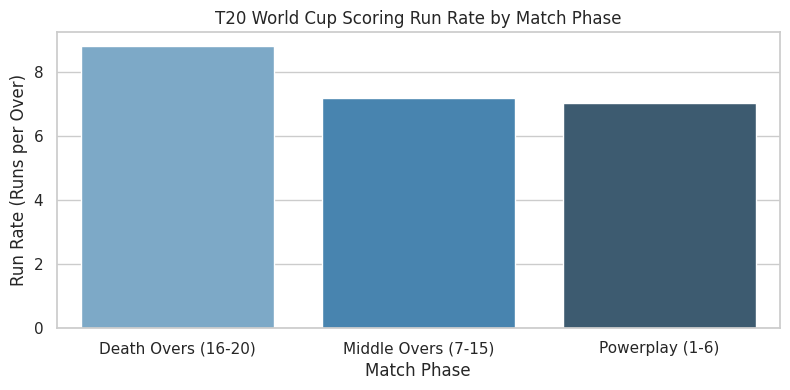

In [33]:
# Group by match phase and compute broadcast telemetry metrics
phase_summary = (
    df.groupby('match_phase')
    .agg(
        total_balls=('ball', 'count'),
        total_runs=('total_runs', 'sum'),
        wickets=('is_wicket', 'sum'),
        dots=('ball_outcome', lambda x: (x == 'Dot Ball').sum()),
        boundaries=('ball_outcome', lambda x: x.isin(['Four', 'Six']).sum()),
    )
    .reset_index()
)

# Run Rate formula: Total Runs / Total Overs (where Total Overs = Total Balls / 6)
phase_summary['run_rate'] = (
    phase_summary['total_runs'] / (phase_summary['total_balls'] / 6)
).round(2)
phase_summary['dot_ball_pct'] = (
    (phase_summary['dots'] / phase_summary['total_balls']) * 100
).round(2)
phase_summary['boundary_pct'] = (
    (phase_summary['boundaries'] / phase_summary['total_balls']) * 100
).round(2)

print('Phase Performance Summary:')
print(
    phase_summary[['match_phase', 'run_rate', 'dot_ball_pct', 'boundary_pct']]
)

# Visualizing Run Rate across phases (fixed palette deprecation warning)
plt.figure(figsize=(8, 4))
sns.barplot(
    data=phase_summary,
    x='match_phase',
    y='run_rate',
    hue='match_phase',
    palette='Blues_d',
    legend=False
)
plt.title('T20 World Cup Scoring Run Rate by Match Phase')
plt.xlabel('Match Phase')
plt.ylabel('Run Rate (Runs per Over)')
plt.tight_layout()
plt.show()

## 4. Over-by-Over Scoring Velocity Curve (Overs 1 to 20)
Tracking scoring trajectory across each individual over to visualize phase acceleration and momentum shifts.

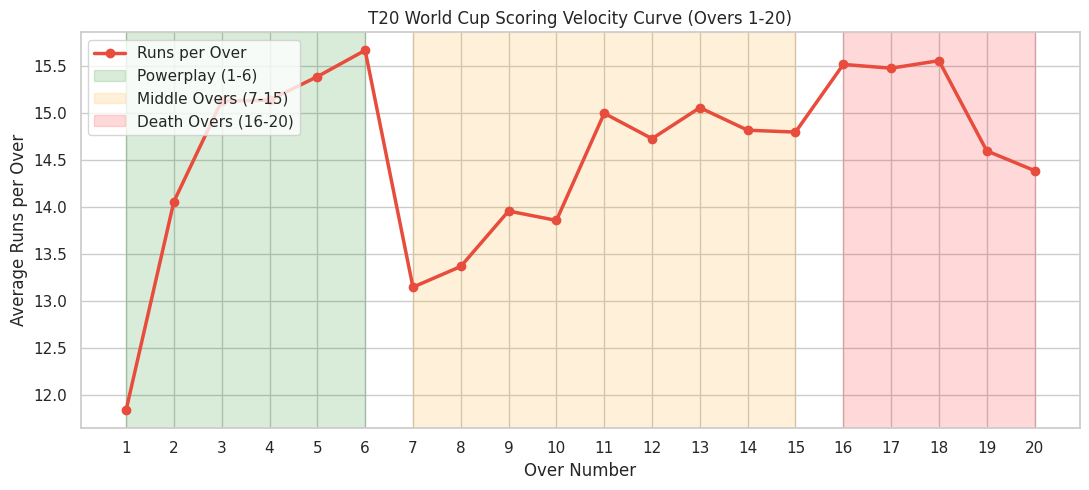

In [34]:
# Calculate average runs per over across all tournament matches
over_stats = (
    df.groupby('over_number')
    .agg(
        total_runs=('total_runs', 'sum'),
        total_matches=('match_id', 'nunique'),
    )
    .reset_index()
)

over_stats['runs_per_over'] = (
    over_stats['total_runs'] / over_stats['total_matches']
).round(2)

plt.figure(figsize=(11, 5))
plt.plot(
    over_stats['over_number'],
    over_stats['runs_per_over'],
    marker='o',
    color='#e74c3c',
    linewidth=2.5,
    label='Runs per Over',
)

# Add phase background shading
plt.axvspan(1, 6, alpha=0.15, color='green', label='Powerplay (1-6)')
plt.axvspan(7, 15, alpha=0.15, color='orange', label='Middle Overs (7-15)')
plt.axvspan(16, 20, alpha=0.15, color='red', label='Death Overs (16-20)')

plt.title('T20 World Cup Scoring Velocity Curve (Overs 1-20)')
plt.xlabel('Over Number')
plt.ylabel('Average Runs per Over')
plt.xticks(range(1, 21))
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

## 5. Batter Efficiency: Strike Rate vs. Dot Ball %
Profiling international batters by plotting scoring aggression against dot-ball control (minimum sample threshold of 120 deliveries faced).

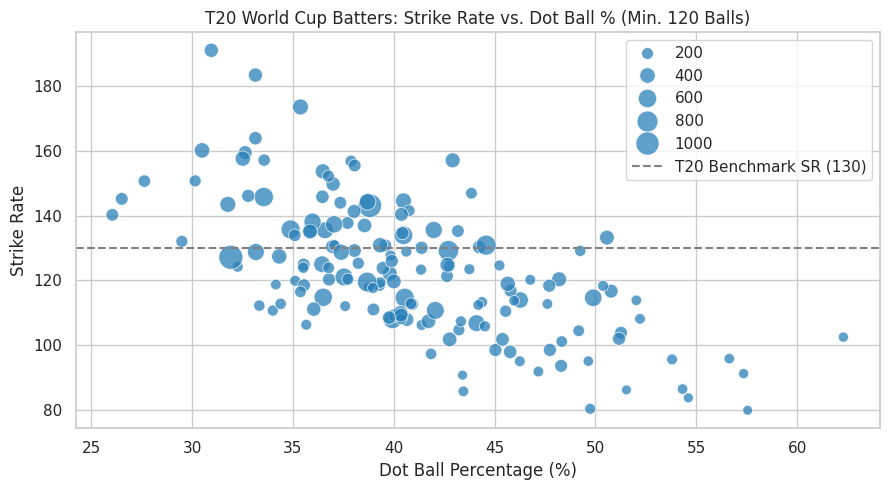

In [35]:
# Aggregate stats for each individual batter ('striker')
batter_stats = (
    df.groupby('striker')
    .agg(
        balls_faced=('ball', 'count'),
        runs_scored=('runs_off_bat', 'sum'),
        dots=('runs_off_bat', lambda x: (x == 0).sum()),
    )
    .reset_index()
)

# Filter for experienced batters (faced at least 120 balls in World Cups)
qualified_batters = batter_stats[batter_stats['balls_faced'] >= 120].copy()

# Calculate Strike Rate and Dot %
qualified_batters['strike_rate'] = (
    (qualified_batters['runs_scored'] / qualified_batters['balls_faced']) * 100
).round(2)
qualified_batters['dot_pct'] = (
    (qualified_batters['dots'] / qualified_batters['balls_faced']) * 100
).round(2)

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=qualified_batters,
    x='dot_pct',
    y='strike_rate',
    size='runs_scored',
    sizes=(50, 300),
    alpha=0.75,
    color='#2980b9',
)

plt.axhline(130, linestyle='--', color='grey', label='T20 Benchmark SR (130)')
plt.title('T20 World Cup Batters: Strike Rate vs. Dot Ball % (Min. 120 Balls)')
plt.xlabel('Dot Ball Percentage (%)')
plt.ylabel('Strike Rate')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 6. Modes of Dismissal
Examining how wickets fall across World Cup matches.

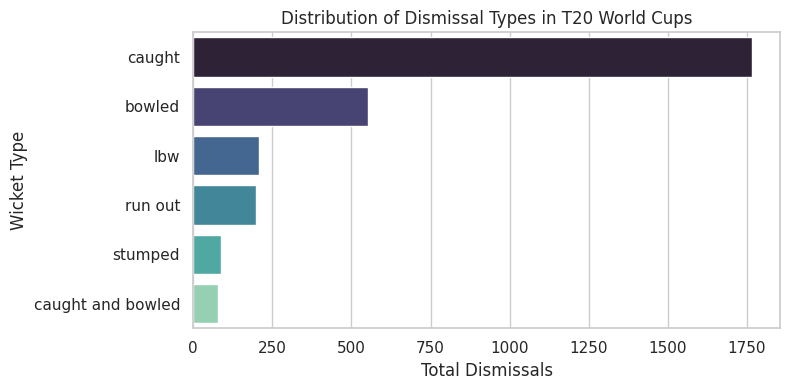

In [36]:
# Filter deliveries where a dismissal occurred
wicket_deliveries = df[
    (df['is_wicket'] == 1) & (df['wicket_type'] != 'None')
]
top_dismissals = wicket_deliveries['wicket_type'].value_counts().head(6)

plt.figure(figsize=(8, 4))
sns.barplot(
    x=top_dismissals.values,
    y=top_dismissals.index,
    hue=top_dismissals.index,
    palette='mako',
    legend=False
)
plt.title('Distribution of Dismissal Types in T20 World Cups')
plt.xlabel('Total Dismissals')
plt.ylabel('Wicket Type')
plt.tight_layout()
plt.show()

## 7. Numerical Feature Correlation Matrix
Evaluating linear correlations between over numbers, runs scored, and extra concessions.

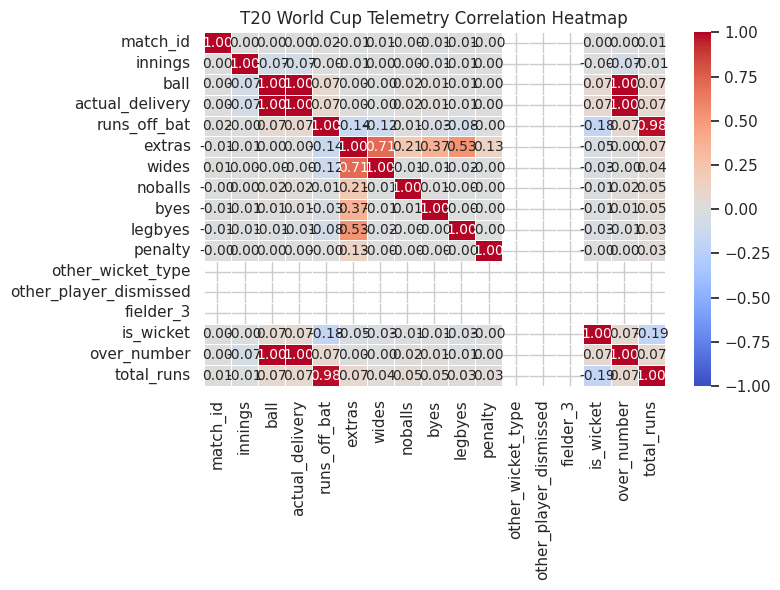

In [37]:
# Select numeric features for correlation
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    annot=True,
    fmt='.2f',
    linewidths=0.5,
)
plt.title('T20 World Cup Telemetry Correlation Heatmap')
plt.tight_layout()
plt.show()

## 8. Key Findings

1. **The Phase Scoring S-Curve:**
   Analysis of match phases reveals a clear tactical progression. Scoring velocity begins at a controlled run rate of ~7.04 RPO during the Powerplay (Overs 1–6), remains steady at ~7.18 RPO through the Middle Overs (7–15), and aggressively surges to ~8.79 RPO in the Death Overs (16–20) as batting sides take maximal risks.
   
2. **Dot-Ball Inversion:**
   Dot-ball pressure is heavily front-loaded. Over 42.99% of all deliveries in the Powerplay are dots due to field restrictions and defensive bowling lines, which drops significantly to ~21.96% in the Death Overs as batters prioritize contact and boundary-hitting.

3. **Dismissal Hazard Distribution:**
   Wickets are heavily concentrated in specific phases, with traditional catching and bowling modes dominating early-over breakthroughs, while deep-field catches spike in the final overs due to high-risk aerial shots.

## 9. Conclusion

This exploratory data analysis successfully moved beyond traditional match-level scorecards to model granular in-match telemetry across ICC Men's T20 World Cup tournaments. By replicating the analytical approaches of modern broadcast engines (such as phase mapping, scoring velocity curves, and batter efficiency scatter profiling), this project highlights how modern international T20 cricket relies heavily on death-over acceleration and dot-ball mitigation. The findings provide objective performance benchmarks that can be extended into predictive modeling or player valuation frameworks.

## 10. Limitations

* **Format Scope:** The dataset is strictly confined to ICC T20 World Cup matches. International tournament dynamics (pressure, shorter sample sizes per team) differ from domestic franchise leagues like the IPL or BBL, where teams play extended seasonal fixtures.
* **Contextual Factors:** Delivery-level logs record event outcomes but do not explicitly quantify external variables such as pitch soil composition, boundary dimensions, weather overhead conditions, or dew factor, all of which heavily influence T20 scoring rates.
* **Associate vs. Full Member Variance:** The dataset includes matches spanning dominant full-member nations and emerging associate nations. Large disparities in skill levels across mismatched fixtures can skew aggregate tournament baselines.